In [1]:
import os, glob, shutil, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

def chuan_bi_du_lieu():
    """Nếu chưa có thư mục data/ thì cho tải lên: một tệp .zip chứa data, hoặc các tệp .csv."""
    if glob.glob("data/*.csv"):
        print("Đã có thư mục data/:", sorted(os.listdir("data")))
        return
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError("Không thấy data/*.csv, hãy đặt thư mục data cạnh notebook.")
    print("Chọn tệp .zip của thư mục data, hoặc chọn cùng lúc các tệp .csv")
    up = files.upload()
    os.makedirs("data", exist_ok=True)
    for ten in list(up):
        if ten.lower().endswith(".zip"):
            zipfile.ZipFile(ten).extractall("_tmp_zip")
        elif ten.lower().endswith(".csv"):
            shutil.move(ten, os.path.join("data", ten))
    for f in glob.glob("_tmp_zip/**/*.csv", recursive=True):
        shutil.copy(f, "data/")
    print("Các tệp trong data/:", sorted(os.listdir("data")))

chuan_bi_du_lieu()

from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def ve_ranh_gioi(model, X, y, ax, tieu_de, cot=("x1", "x2")):
    """Vẽ ranh giới quyết định của mô hình hai đặc trưng."""
    X = np.asarray(X)
    gx, gy = np.meshgrid(np.linspace(X[:, 0].min() - .3, X[:, 0].max() + .3, 250),
                         np.linspace(X[:, 1].min() - .3, X[:, 1].max() + .3, 250))
    luoi = pd.DataFrame(np.c_[gx.ravel(), gy.ravel()], columns=list(cot))
    z = model.predict(luoi).reshape(gx.shape)
    ax.contourf(gx, gy, z, alpha=0.25, cmap="coolwarm", levels=[-.5, .5, 1.5])
    ax.scatter(X[:, 0], X[:, 1], c=np.asarray(y), cmap="coolwarm", edgecolor="white", s=18)
    ax.set_title(tieu_de, fontsize=10); ax.grid(False)

Chọn tệp .zip của thư mục data, hoặc chọn cùng lúc các tệp .csv


Saving gia_nha.csv to gia_nha.csv
Saving hai_vang_trang.csv to hai_vang_trang.csv
Saving sinh_vien_mo_rong.csv to sinh_vien_mo_rong.csv
Saving xor.csv to xor.csv
Các tệp trong data/: ['gia_nha.csv', 'hai_vang_trang.csv', 'sinh_vien_mo_rong.csv', 'xor.csv']


## 2. Tự tính lan truyền tiến

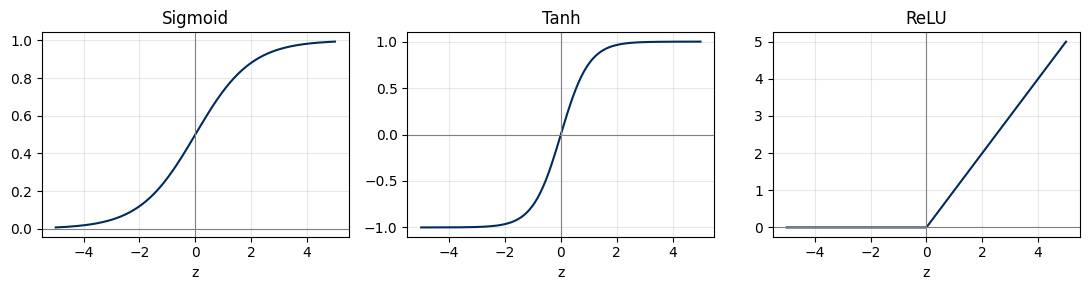

Một nơ-ron:
  z = 0.8*2.0 + (-0.5)*1.0 + 0.3*3.0 + (-0.2) = 1.80
  a = sigmoid(z) = 0.8581

Mạng giải XOR:
 x1 x2 h1 h2  y
  0  0  0  0  0
  0  1  1  0  1
  1  0  1  0  1
  1  1  2  1  0

Tính cả bằng một lần: [0. 1. 1. 0.]


In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def relu(z):
    return np.maximum(0, z)

# Hình 1: ba hàm kích hoạt
z_ = np.linspace(-5, 5, 200)
fig, axs = plt.subplots(1, 3, figsize=(11, 3))
for ax, (ten, f) in zip(axs, [("Sigmoid", sigmoid), ("Tanh", np.tanh), ("ReLU", relu)]):
    ax.plot(z_, f(z_), color="#002b5c"); ax.axhline(0, color="gray", lw=.8); ax.axvline(0, color="gray", lw=.8)
    ax.set_title(ten); ax.set_xlabel("z")
plt.tight_layout(); plt.show()

# Phần 1: một nơ-ron với hàm sigmoid, chính là hồi quy logistic
w = np.array([0.8, -0.5, 0.3])
b = -0.2
x = np.array([2.0, 1.0, 3.0])
z = w @ x + b
print("Một nơ-ron:")
print(f"  z = {w[0]}*{x[0]} + ({w[1]})*{x[1]} + {w[2]}*{x[2]} + ({b}) = {z:.2f}")
print(f"  a = sigmoid(z) = {sigmoid(z):.4f}\n")

# Phần 2: mạng 2 đầu vào, 2 nơ-ron ẩn ReLU, 1 nơ-ron ra
W1 = np.array([[1.0, 1.0],    # cột 1: trọng số vào nơ-ron ẩn h1
               [1.0, 1.0]])   # cột 2: trọng số vào nơ-ron ẩn h2
b1 = np.array([0.0, -1.0])
W2 = np.array([1.0, -2.0])
b2 = 0.0

X4 = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
print("Mạng giải XOR:")
print(" x1 x2 h1 h2  y")
for xx in X4:
    h = relu(xx @ W1 + b1)   # lớp ẩn
    y_ = h @ W2 + b2         # lớp ra
    print(f"  {xx[0]:.0f}  {xx[1]:.0f}  {h[0]:.0f}  {h[1]:.0f}  {y_:.0f}")
print()

# Cả bốn đầu vào cùng lúc bằng phép nhân ma trận
H = relu(X4 @ W1 + b1)
Y = H @ W2 + b2
print("Tính cả bằng một lần:", Y)

## 3. Một nơ-ron và một lớp ẩn trên XOR

Hồi quy logistic: 0.4500

Số nơ-ron ẩn  số tham số  tập học  tập kiểm tra
    1             5       0.6533    0.6900
    2             9       0.6533    0.6900
    4            17       0.9033    0.9300
    8            33       0.9167    0.9100


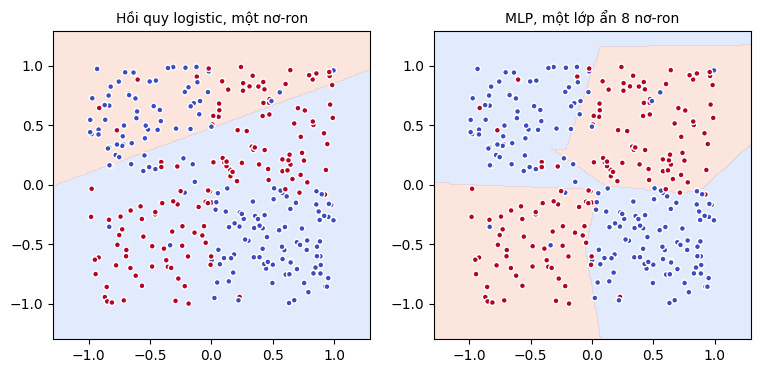

In [3]:
from sklearn.linear_model import LogisticRegression

df = pd.read_csv("data/xor.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)

lr = LogisticRegression().fit(X_tr, y_tr)
print(f"Hồi quy logistic: {accuracy_score(y_te, lr.predict(X_te)):.4f}\n")

# Dữ liệu nhỏ nên dùng solver="lbfgs", học nhanh và ổn định hơn
print("Số nơ-ron ẩn  số tham số  tập học  tập kiểm tra")
mlp8 = None
for so in [1, 2, 4, 8]:
    mlp = MLPClassifier(hidden_layer_sizes=(so,), solver="lbfgs", max_iter=5000, random_state=0)
    mlp.fit(X_tr, y_tr)
    # coefs_ là danh sách ma trận trọng số, intercepts_ là hệ số chặn
    so_ts = sum(w_.size for w_ in mlp.coefs_) + sum(b_.size for b_ in mlp.intercepts_)
    a_hoc = accuracy_score(y_tr, mlp.predict(X_tr))
    a_kt = accuracy_score(y_te, mlp.predict(X_te))
    print(f"   {so:2d}           {so_ts:3d}       {a_hoc:.4f}    {a_kt:.4f}")
    if so == 8: mlp8 = mlp

fig, axs = plt.subplots(1, 2, figsize=(9, 4))
ve_ranh_gioi(lr, X_tr, y_tr, axs[0], "Hồi quy logistic, một nơ-ron")
ve_ranh_gioi(mlp8, X_tr, y_tr, axs[1], "MLP, một lớp ẩn 8 nơ-ron")
plt.show()

## 4. Độ lớn mạng và điều chuẩn

Ba mạng              tập học  tập kiểm tra
  (2,), alpha 1e-4   0.8444   0.8533
  (100, 100), 1e-5   1.0000   0.7733
  (100, 100), 1.0    0.8844   0.9067


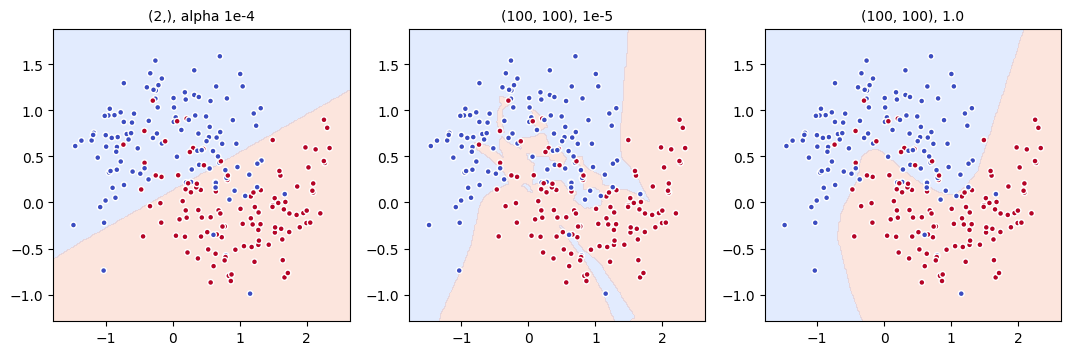


alpha    kiểm định chéo
  1e-05    0.7822
  0.001    0.7822
  0.1      0.7689
  1.0      0.8578
  3.0      0.8400
  10.0     0.8356
alpha tốt nhất = 1.0, tập kiểm tra 0.9067


In [13]:
df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)

def mang(lop_an, alpha):
    return make_pipeline(
        StandardScaler(),
        MLPClassifier(hidden_layer_sizes=lop_an, alpha=alpha, solver="lbfgs", max_iter=20000, random_state=0),
    )

cau_hinh = [("(2,), alpha 1e-4", (2,), 1e-4), ("(100, 100), 1e-5", (100, 100), 1e-5), ("(100, 100), 1.0", (100, 100), 1.0)]
print("Ba mạng              tập học  tập kiểm tra")
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (ten, lop_an, alpha) in zip(axs, cau_hinh):
    m = mang(lop_an, alpha).fit(X_tr, y_tr)
    print(f"  {ten:18s} {accuracy_score(y_tr, m.predict(X_tr)):.4f}   {accuracy_score(y_te, m.predict(X_te)):.4f}")
    ve_ranh_gioi(m, X_tr, y_tr, ax, ten)
plt.show()
print()

# Chọn alpha bằng kiểm định chéo, chỉ trên tập học
print("alpha    kiểm định chéo")
diem = {}
for alpha in [1e-5, 1e-3, 0.1, 1.0, 3.0, 10.0]:
    diem[alpha] = cross_val_score(mang((100, 100), alpha), X_tr, y_tr, cv=5).mean()
    print(f"  {alpha:<8} {diem[alpha]:.4f}")
a_tot = max(diem, key=diem.get)
m = mang((100, 100), a_tot).fit(X_tr, y_tr)
print(f"alpha tốt nhất = {a_tot}, tập kiểm tra {accuracy_score(y_te, m.predict(X_te)):.4f}")

## 5. Mạng nơ-ron khi quên chuẩn hoá

In [5]:
df = pd.read_csv("data/sinh_vien_mo_rong.csv")
X = df[["gio_on", "diem_giua_ky", "chi_tieu"]]
y = df["qua_mon"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)

tho = MLPClassifier(hidden_layer_sizes=(20,), max_iter=3000, random_state=0).fit(X_tr, y_tr)
chuan = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(20,), max_iter=3000, random_state=0),
).fit(X_tr, y_tr)

print(f"Đoán bừa cả lớp qua : {y_te.mean():.4f}")
print(f"Không chuẩn hoá     : {accuracy_score(y_te, tho.predict(X_te)):.4f}")
print(f"Có chuẩn hoá        : {accuracy_score(y_te, chuan.predict(X_te)):.4f}\n")

# Mạng không chuẩn hoá đoán ra sao
du = tho.predict(X_te)
print("Không chuẩn hoá, số bạn đoán qua:", du.sum(), "trên", len(du))

Đoán bừa cả lớp qua : 0.6000
Không chuẩn hoá     : 0.4000
Có chuẩn hoá        : 0.9000

Không chuẩn hoá, số bạn đoán qua: 0 trên 30


## 6. Nhận dạng chữ số viết tay

Kích thước các ma trận trọng số: [(64, 100), (100, 10)]
Tổng số tham số: 7510
Số vòng học: 144
Mất mát vòng 1: 2.5206, vòng 10: 0.4448, vòng cuối: 0.0052

Accuracy trên tập kiểm tra: 0.9844
Số ảnh đoán sai: 7 trên 450
  ảnh   6: thật là 9, đoán là 3
  ảnh  61: thật là 5, đoán là 7
  ảnh  77: thật là 2, đoán là 1
  ảnh  85: thật là 9, đoán là 7
  ảnh 276: thật là 8, đoán là 2
  ảnh 428: thật là 7, đoán là 9
  ảnh 443: thật là 4, đoán là 7

Dừng sớm sau 44 vòng, accuracy 0.9578

Logistic có chuẩn hoá  0.9711
KNN, k = 5             0.9867
SVM kernel RBF         0.9911


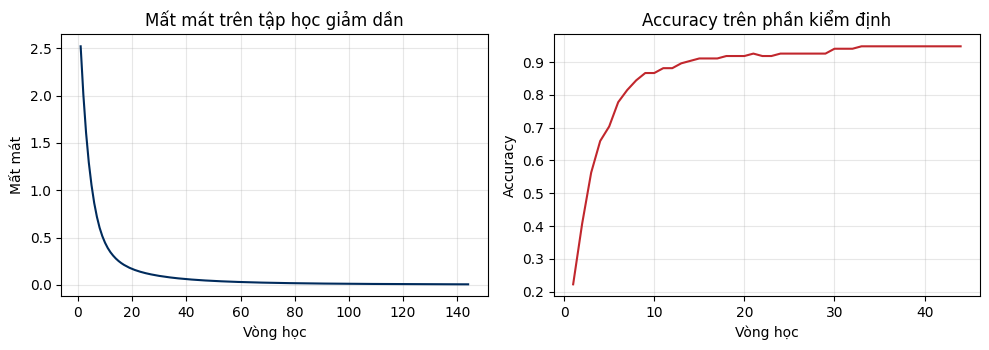

In [6]:
from sklearn.datasets import load_digits
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)

mang_so = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000, random_state=0),
).fit(X_tr, y_tr)
mlp = mang_so[-1]

print("Kích thước các ma trận trọng số:", [w_.shape for w_ in mlp.coefs_])
so_ts = sum(w_.size for w_ in mlp.coefs_) + sum(b_.size for b_ in mlp.intercepts_)
print("Tổng số tham số:", so_ts)
print("Số vòng học:", mlp.n_iter_)
mm = mlp.loss_curve_
print(f"Mất mát vòng 1: {mm[0]:.4f}, vòng 10: {mm[9]:.4f}, vòng cuối: {mm[-1]:.4f}\n")

du = mang_so.predict(X_te)
print(f"Accuracy trên tập kiểm tra: {accuracy_score(y_te, du):.4f}")
sai = np.flatnonzero(du != y_te)
print("Số ảnh đoán sai:", len(sai), "trên", len(y_te))
for i in sai:
    print(f"  ảnh {i:3d}: thật là {y_te[i]}, đoán là {du[i]}")
print()

# Dừng sớm: giữ riêng 10% tập học để theo dõi
dung_som = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000, early_stopping=True, random_state=0),
).fit(X_tr, y_tr)
print("Dừng sớm sau", dung_som[-1].n_iter_, "vòng, accuracy", f"{accuracy_score(y_te, dung_som.predict(X_te)):.4f}\n")

# So với các mô hình đã học
khac = {
    "Logistic có chuẩn hoá": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "KNN, k = 5": KNeighborsClassifier(),
    "SVM kernel RBF": SVC(),
}
for ten, mh in khac.items():
    acc = accuracy_score(y_te, mh.fit(X_tr, y_tr).predict(X_te))
    print(f"{ten:22s} {acc:.4f}")

# Hình 4: đường mất mát và accuracy phần kiểm định (dừng sớm)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
axs[0].plot(range(1, len(mm) + 1), mm, color="#002b5c"); axs[0].set_title("Mất mát trên tập học giảm dần")
axs[0].set_xlabel("Vòng học"); axs[0].set_ylabel("Mất mát")
vs = dung_som[-1].validation_scores_
axs[1].plot(range(1, len(vs) + 1), vs, color="#c1272d"); axs[1].set_title("Accuracy trên phần kiểm định")
axs[1].set_xlabel("Vòng học"); axs[1].set_ylabel("Accuracy")
plt.tight_layout(); plt.show()

## 7. Bài tập

### Bài tập 1: Tự dự đoán bằng trọng số đã học

In [7]:
df = pd.read_csv("data/xor.csv")
X = df[["x1", "x2"]]; y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)

mlp = MLPClassifier(hidden_layer_sizes=(8,), solver="lbfgs", max_iter=5000, random_state=0).fit(X_tr, y_tr)
X5 = X_te.to_numpy()[:5]

# Tự tính lan truyền tiến: lớp ẩn ReLU, lớp ra sigmoid
H = relu(X5 @ mlp.coefs_[0] + mlp.intercepts_[0])
p_tu_tinh = sigmoid(H @ mlp.coefs_[1] + mlp.intercepts_[1]).ravel()
p_thu_vien = mlp.predict_proba(X_te.iloc[:5])[:, 1]

print("Tự tính     :", np.round(p_tu_tinh, 10))
print("predict_proba:", np.round(p_thu_vien, 10))
print("Sai lệch lớn nhất:", np.abs(p_tu_tinh - p_thu_vien).max())
print("Khớp nhau:", np.allclose(p_tu_tinh, p_thu_vien, atol=1e-10))

Tự tính     : [0.01775032 0.99946016 0.79969969 0.13650667 0.95776552]
predict_proba: [0.01775032 0.99946016 0.79969969 0.13650667 0.95776552]
Sai lệch lớn nhất: 0.0
Khớp nhau: True


### Bài tập 2: Một mạng XOR khác

In [8]:
X4 = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
print(" x1 x2 h1 h2  y  XOR")
for a, b_ in X4:
    h1 = max(0, a - b_)
    h2 = max(0, b_ - a)
    yy = h1 + h2
    print(f"  {a:.0f}  {b_:.0f}  {h1:.0f}  {h2:.0f}  {yy:.0f}   {int(a) ^ int(b_)}")
# Bản ma trận
W1 = np.array([[1, -1], [-1, 1]], dtype=float); W2 = np.array([1.0, 1.0])
Y = relu(X4 @ W1) @ W2
print("Bằng ma trận:", Y, "| đúng XOR:", np.array_equal(Y, [0, 1, 1, 0]))

 x1 x2 h1 h2  y  XOR
  0  0  0  0  0   0
  0  1  0  1  1   1
  1  0  1  0  1   1
  1  1  0  0  0   0
Bằng ma trận: [0. 1. 1. 0.] | đúng XOR: True


### Bài tập 3: So các hàm kích hoạt trên bộ hai vầng trăng

In [9]:
df = pd.read_csv("data/hai_vang_trang.csv")
X = df[["x1", "x2"]]; y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=17, stratify=y)

kq = []
for act in ["logistic", "tanh", "relu"]:
    m = make_pipeline(StandardScaler(),
                      MLPClassifier(hidden_layer_sizes=(100, 100), alpha=1.0, activation=act,
                                    solver="lbfgs", max_iter=20000, random_state=0)).fit(X_tr, y_tr)
    kq.append([act, accuracy_score(y_tr, m.predict(X_tr)), accuracy_score(y_te, m.predict(X_te))])
bang = pd.DataFrame(kq, columns=["activation", "tập học", "tập kiểm tra"]).round(4)
display(bang)
print("Hàm cho tập kiểm tra tốt nhất:", bang.loc[bang["tập kiểm tra"].idxmax(), "activation"])

,activation,tập học,tập kiểm tra
0,logistic,0.8400,0.8533
1,tanh,0.8711,0.9067
2,relu,0.8844,0.9067


Hàm cho tập kiểm tra tốt nhất: tanh


### Bài tập 4: Tốc độ học (bộ chữ số)

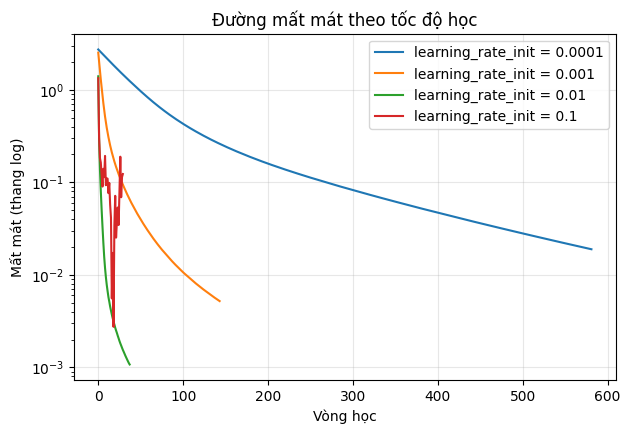

,learning_rate_init,n_iter_,mất mát cuối,accuracy kiểm tra
0,0.0001,582,0.0189,0.9889
1,0.0010,144,0.0052,0.9844
2,0.0100,38,0.0011,0.9778
3,0.1000,30,0.1230,0.9667


In [10]:
Xd, yd = load_digits(return_X_y=True)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.25, random_state=17, stratify=yd)

kq = []
plt.figure(figsize=(7, 4.5))
for lr_ in [0.0001, 0.001, 0.01, 0.1]:
    m = make_pipeline(StandardScaler(),
                      MLPClassifier(hidden_layer_sizes=(100,), learning_rate_init=lr_,
                                    solver="adam", max_iter=1000, random_state=0)).fit(Xd_tr, yd_tr)
    mm = m[-1]
    kq.append([lr_, mm.n_iter_, mm.loss_, accuracy_score(yd_te, m.predict(Xd_te))])
    plt.plot(mm.loss_curve_, label=f"learning_rate_init = {lr_}")
plt.yscale("log"); plt.xlabel("Vòng học"); plt.ylabel("Mất mát (thang log)")
plt.title("Đường mất mát theo tốc độ học"); plt.legend()
plt.savefig("toc_do_hoc.png", dpi=150, bbox_inches="tight"); plt.show()
display(pd.DataFrame(kq, columns=["learning_rate_init", "n_iter_", "mất mát cuối", "accuracy kiểm tra"]).round(4))

### Bài tập 5: Dò lưới cho mạng nơ-ron

In [11]:
from sklearn.model_selection import GridSearchCV

pipe = make_pipeline(StandardScaler(), MLPClassifier(max_iter=1000, random_state=0))
luoi = {"mlpclassifier__hidden_layer_sizes": [(10,), (50,), (100,), (50, 50)],
        "mlpclassifier__alpha": [0.0001, 0.01, 1]}
gs = GridSearchCV(pipe, luoi, cv=5, n_jobs=-1).fit(Xd_tr, yd_tr)
print("Cặp tốt nhất:", gs.best_params_)
print(f"Accuracy kiểm định chéo: {gs.best_score_:.4f}")
acc_mlp = accuracy_score(yd_te, gs.predict(Xd_te))
acc_svm = accuracy_score(yd_te, SVC().fit(Xd_tr, yd_tr).predict(Xd_te))
print(f"Tập kiểm tra, MLP tốt nhất: {acc_mlp:.4f}")
print(f"Tập kiểm tra, SVM RBF     : {acc_svm:.4f}")
print("MLP có vượt SVM không?", "CÓ" if acc_mlp > acc_svm else "KHÔNG")
kq = pd.DataFrame(gs.cv_results_)[["param_mlpclassifier__hidden_layer_sizes", "param_mlpclassifier__alpha", "mean_test_score"]]
display(kq.sort_values("mean_test_score", ascending=False).round(4).head(6))

Cặp tốt nhất: {'mlpclassifier__alpha': 1, 'mlpclassifier__hidden_layer_sizes': (50,)}
Accuracy kiểm định chéo: 0.9785
Tập kiểm tra, MLP tốt nhất: 0.9822
Tập kiểm tra, SVM RBF     : 0.9911
MLP có vượt SVM không? KHÔNG


,param_mlpclassifier__hidden_layer_sizes,param_mlpclassifier__alpha,mean_test_score
9,"(50,)",1.0000,0.9785
11,"(50, 50)",1.0000,0.9777
10,"(100,)",1.0000,0.9777
2,"(100,)",0.0001,0.9755
6,"(100,)",0.0100,0.9755
5,"(50,)",0.0100,0.9755


### Bài tập 6: Mạng nơ-ron cho hồi quy (giá nhà, bài 1)

Tệp: data/gia_nha.csv | cột giá: gia | cột diện tích: dien_tich | cột đặc trưng: ['dien_tich', 'so_phong', 'tuoi_nha']
MAE hồi quy tuyến tính: 0.2185
MAE mạng nơ-ron       : 0.4242

Diện tích lớn nhất trong tập học: 115.9 m2
Dự đoán căn 250 m2, hồi quy tuyến tính: 18.4684
Dự đoán căn 250 m2, mạng nơ-ron       : 20.9259


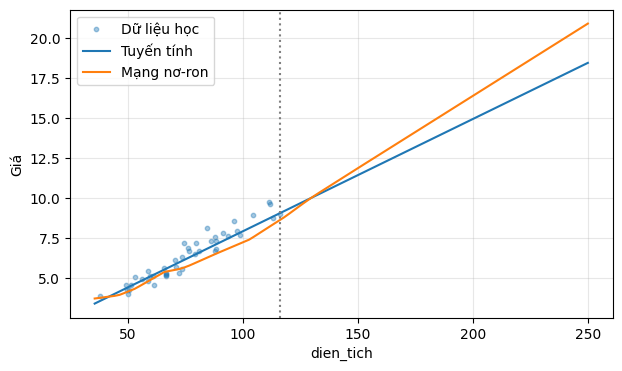

In [12]:
def doc_du_lieu_gia_nha():
    """Tìm tệp giá nhà của bài 1 trong data/. Nếu tự động đoán sai cột, sửa 3 biến CẤU HÌNH bên dưới."""
    TEP = None        # CẤU HÌNH: ví dụ "data/gia_nha.csv"
    COT_GIA = None    # CẤU HÌNH: tên cột giá nhà
    COT_DIEN_TICH = None  # CẤU HÌNH: tên cột diện tích (m2)
    if TEP is None:
        ds = glob.glob("data/*.csv")
        uu_tien = [f for f in ds if any(k in os.path.basename(f).lower() for k in ["nha", "house", "price"])]
        if not uu_tien:
            raise FileNotFoundError("Không tìm thấy tệp giá nhà trong data/, hãy điền biến TEP.")
        TEP = sorted(uu_tien)[0]
    d = pd.read_csv(TEP).select_dtypes("number").dropna()
    if COT_GIA is None:
        ung = [c for c in d.columns if any(k in c.lower() for k in ["gia", "price"])]
        COT_GIA = ung[0] if ung else d.columns[-1]
    if COT_DIEN_TICH is None:
        ung = [c for c in d.columns if c != COT_GIA and any(k in c.lower() for k in ["dien_tich", "dt", "m2", "area"])]
        COT_DIEN_TICH = ung[0] if ung else [c for c in d.columns if c != COT_GIA][0]
    print(f"Tệp: {TEP} | cột giá: {COT_GIA} | cột diện tích: {COT_DIEN_TICH} | cột đặc trưng: {[c for c in d.columns if c != COT_GIA]}")
    return d.drop(columns=COT_GIA), d[COT_GIA], COT_DIEN_TICH

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.neural_network import MLPRegressor

Xn, yn, cot_dt = doc_du_lieu_gia_nha()
Xn_tr, Xn_te, yn_tr, yn_te = train_test_split(Xn, yn, test_size=0.25, random_state=17)

tt = LinearRegression().fit(Xn_tr, yn_tr)
nn = make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(20,), max_iter=5000, random_state=0)).fit(Xn_tr, yn_tr)
print(f"MAE hồi quy tuyến tính: {mean_absolute_error(yn_te, tt.predict(Xn_te)):,.4f}")
print(f"MAE mạng nơ-ron       : {mean_absolute_error(yn_te, nn.predict(Xn_te)):,.4f}")

# Dự đoán căn 250 m2: các đặc trưng khác lấy trung vị của tập học
canh = pd.DataFrame([Xn_tr.median()])
canh[cot_dt] = 250
print(f"\nDiện tích lớn nhất trong tập học: {Xn_tr[cot_dt].max():.1f} m2")
print(f"Dự đoán căn 250 m2, hồi quy tuyến tính: {tt.predict(canh)[0]:,.4f}")
print(f"Dự đoán căn 250 m2, mạng nơ-ron       : {nn.predict(canh)[0]:,.4f}")

# Vẽ đường dự đoán theo diện tích để thấy ngoại suy
dt = np.linspace(Xn[cot_dt].min(), max(250, Xn[cot_dt].max()), 100)
luoi_dt = pd.concat([canh] * len(dt), ignore_index=True); luoi_dt[cot_dt] = dt
plt.figure(figsize=(7, 4))
plt.scatter(Xn_tr[cot_dt], yn_tr, s=10, alpha=.4, label="Dữ liệu học")
plt.plot(dt, tt.predict(luoi_dt), label="Tuyến tính"); plt.plot(dt, nn.predict(luoi_dt), label="Mạng nơ-ron")
plt.axvline(Xn_tr[cot_dt].max(), color="gray", ls=":"); plt.xlabel(cot_dt); plt.ylabel("Giá"); plt.legend(); plt.show()